# Разведочный анализ данных (EDA)
### Исследование качества датасета CoRE MOF

**Главная цель анализа** — оценить чистоту данных, найти скрытые аномалии и пропуски.



In [73]:
import pandas as pd 
import matplotlib.pyplot as plt
from scipy.stats import zscore
import seaborn as sns



## 1. Загрузка файла в формате Parquet и первичный анализ структуры

На данном этапе выполняется чтение исходного датасета из оптимизированного формата Parquet. Выводятся данные из начала и случайного места DataFrame. Представлена размерность исходного датасета. Проверены типы данных. Загрузка датасета с гугл диска, приведение типов данных и приведение к формату Parquet осущесвляется в скрипте data_loader.py.




In [74]:
from pathlib import Path
DATA_PATH = Path.cwd().parent / 'dataset.parquet'
df = pd.read_parquet(DATA_PATH)

df.head(5)


,filename,LCD,PLD,LFPD,cm3_g,ASA_m2_cm3,ASA_m2_g,NASA_m2_cm3,NASA_m2_g,AV_VF,...,Unnamed: 32,Unnamed: 33,Unnamed: 34,Unnamed: 35,Unnamed: 36,Unnamed: 37,Unnamed: 38,Unnamed: 39,Unnamed: 40,Unnamed: 41
0,ABAVIJ_clean,4.45543,2.49720,4.40652,1.524930,0.000000,0.000000,312.052002,204.632996,0.3792,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,ABAVOP_clean,3.53642,2.44162,3.53007,1.565940,0.000000,0.000000,122.781998,78.407898,0.3782,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,ABAYIO_clean,11.39486,4.32260,11.27409,0.949126,1428.729980,1505.310059,409.493988,431.444000,0.6636,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,ABAYOU_clean,11.27344,4.51080,11.27344,0.979267,1463.420044,1494.400024,419.062012,427.934998,0.6638,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,ABEFUL_clean,4.93969,3.32948,4.93889,1.551080,418.489990,269.806000,0.000000,0.000000,0.4118,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [75]:
df.sample(5, random_state=42)

,filename,LCD,PLD,LFPD,cm3_g,ASA_m2_cm3,ASA_m2_g,NASA_m2_cm3,NASA_m2_g,AV_VF,...,Unnamed: 32,Unnamed: 33,Unnamed: 34,Unnamed: 35,Unnamed: 36,Unnamed: 37,Unnamed: 38,Unnamed: 39,Unnamed: 40,Unnamed: 41
5787,MANDUD_clean,8.14470,5.93208,8.14470,0.901348,2323.100098,2577.360107,0.000000,0.000000,0.6668,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9156,TONWUO01_clean,5.10073,4.40085,5.10073,1.209390,753.801025,623.288025,0.000000,0.000000,0.4534,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10776,XAPCOJ_clean,7.18852,7.02354,7.18852,1.112260,1622.089966,1458.369995,0.000000,0.000000,0.6008,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10696,XAGDAL_SL,5.19312,2.42079,5.19224,2.153990,0.000000,0.000000,616.354004,286.144989,0.4096,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
11301,YIGFIF_clean,4.44183,3.32862,4.38530,1.974850,296.299988,150.037003,281.803986,142.695999,0.4704,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [76]:
print(f"Размерность датасета: {df.shape}")


Размерность датасета: (14142, 42)


In [77]:
df.dtypes

filename                          str
LCD                           float32
PLD                           float32
LFPD                          float32
cm3_g                         float32
ASA_m2_cm3                    float32
ASA_m2_g                      float32
NASA_m2_cm3                   float32
NASA_m2_g                     float32
AV_VF                         float32
AV_cm3_g                      float32
NAV_cm3_g                     float32
All_Metals                   category
Has_OMS                          bool
Open_Metal_Sites                  str
Extension                    category
FSR_overlap                      bool
from_CSD                         bool
public                           bool
DISORDER                          str
CSD_overlap_inCoRE               bool
CSD_of_WoS_inCoRE                 str
CSD_overlap_inCCDC               bool
date_CSD                          str
DOI_public                        str
Note                              str
Matched_CSD_

## 2. Анализ полноты данных и очистка

Для оценки целостности данных рассчитывается количество пропусков по столбцам, а также их относительная доля в процентах по каждому доступному признаку. 



In [78]:
missing_values = df.isna().sum()
missing_percent = df.isna().mean() * 100

missing_table = pd.DataFrame({'Missing Values': missing_values,'Percentage': missing_percent})
missing_table


,Missing Values,Percentage
filename,0,0.000000
LCD,0,0.000000
PLD,0,0.000000
LFPD,0,0.000000
cm3_g,0,0.000000
ASA_m2_cm3,0,0.000000
ASA_m2_g,0,0.000000
NASA_m2_cm3,0,0.000000
NASA_m2_g,0,0.000000
AV_VF,0,0.000000


### Автоматические предупреждения 

Запускается скрипт, который показывает критические зоны (где пропусков больше 70% и 95%).


In [79]:
for col in missing_table.index:
    percent = missing_table.loc[col, 'Percentage']
    if percent > 95:
        print(f"КРИТИЧЕСКОЕ ПРЕДУПРЕЖДЕНИЕ!!! Колонка '{col}' имеет {percent:.2f}% пропущенных значений. Рекомендуется удалить эту колонку из анализа.")
    elif percent > 70:
        print(f"ПРЕДУПРЕЖДЕНИЕ: Колонка '{col}' имеет {percent:.2f}% пропущенных значений. Рекомендуется рассмотреть возможность удаления этой колонки из анализа.")

ПРЕДУПРЕЖДЕНИЕ: Колонка 'DISORDER' имеет 83.39% пропущенных значений. Рекомендуется рассмотреть возможность удаления этой колонки из анализа.
КРИТИЧЕСКОЕ ПРЕДУПРЕЖДЕНИЕ!!! Колонка 'CSD_of_WoS_inCoRE' имеет 97.31% пропущенных значений. Рекомендуется удалить эту колонку из анализа.
КРИТИЧЕСКОЕ ПРЕДУПРЕЖДЕНИЕ!!! Колонка 'date_CSD' имеет 96.87% пропущенных значений. Рекомендуется удалить эту колонку из анализа.
КРИТИЧЕСКОЕ ПРЕДУПРЕЖДЕНИЕ!!! Колонка 'DOI_public' имеет 96.87% пропущенных значений. Рекомендуется удалить эту колонку из анализа.
КРИТИЧЕСКОЕ ПРЕДУПРЕЖДЕНИЕ!!! Колонка 'Note' имеет 96.87% пропущенных значений. Рекомендуется удалить эту колонку из анализа.
КРИТИЧЕСКОЕ ПРЕДУПРЕЖДЕНИЕ!!! Колонка 'Matched_CSD_of_CoRE' имеет 96.87% пропущенных значений. Рекомендуется удалить эту колонку из анализа.
КРИТИЧЕСКОЕ ПРЕДУПРЕЖДЕНИЕ!!! Колонка 'Possible_List_CSD_of_CoRE' имеет 99.24% пропущенных значений. Рекомендуется удалить эту колонку из анализа.
КРИТИЧЕСКОЕ ПРЕДУПРЕЖДЕНИЕ!!! Колонка 'Unna

### Очистка данных 

**Что мы удаляем и почему:**
* **Служебные метаданные баз данных (CSD / CCDC / WoS):** Колонки `CSD_of_WoS_inCoRE`, `date_CSD`, `DOI_public`, `Note`, `Matched_CSD_of_CoRE`, `Possible_List_CSD_of_CoRE` и пустые поля `Unnamed`содержали критический объем пропусков (до **99.9%**). Это просто индексы перекрестных ссылок внешних каталогов. Физического смысла в них нет. 

* **Технические флаги (`from_CSD`, `public`, `FSR_overlap`):** Заполнены на 100%, но содержат бинарные метки публикации. Данные поля не несут физико-химического или геометрического смысла пористой структуры (таких как пористость, диаметр пор или площадь поверхности) и избыточны для дальнейших аналитических задач. 

**Что мы оставляем:**
* **Колонка `DISORDER` (разупорядоченность кристаллической решетки):** содержит 83.39% пропусков. Несмотря на высокую разреженность, этот параметр является критически важным физическим фактором при анализе дефектов и стабильности металл-органических каркасов (MOF). Признак осознанно сохранен в датасете для проведения дальнейшего специфического анализа.


In [80]:
columns_to_remove = [
    'CSD_of_WoS_inCoRE',
    'date_CSD',
    'DOI_public',
    'Note',
    'Matched_CSD_of_CoRE',
    'Possible_List_CSD_of_CoRE',
    'FSR_overlap',
    'from_CSD',
    'public',
    'CSD_overlap_inCoRE',
    'CSD_overlap_inCCDC'
]

unnamed_cols = [col for col in df.columns if 'Unnamed:' in col]
columns_to_remove.extend(unnamed_cols)
df = df.drop(columns=columns_to_remove, errors='ignore')

print(f"Размерность датасета после удаления колонок: {df.shape}")
df.head(5)


Размерность датасета после удаления колонок: (14142, 17)


,filename,LCD,PLD,LFPD,cm3_g,ASA_m2_cm3,ASA_m2_g,NASA_m2_cm3,NASA_m2_g,AV_VF,AV_cm3_g,NAV_cm3_g,All_Metals,Has_OMS,Open_Metal_Sites,Extension,DISORDER
0,ABAVIJ_clean,4.45543,2.49720,4.40652,1.524930,0.000000,0.000000,312.052002,204.632996,0.3792,0.248667,0.0,Co,False,,clean,NaN
1,ABAVOP_clean,3.53642,2.44162,3.53007,1.565940,0.000000,0.000000,122.781998,78.407898,0.3782,0.241516,0.0,Co,False,,clean,NaN
2,ABAYIO_clean,11.39486,4.32260,11.27409,0.949126,1428.729980,1505.310059,409.493988,431.444000,0.6636,0.699170,0.0,Mn,False,,clean,NaN
3,ABAYOU_clean,11.27344,4.51080,11.27344,0.979267,1463.420044,1494.400024,419.062012,427.934998,0.6638,0.677854,0.0,Co,False,,clean,NaN
4,ABEFUL_clean,4.93969,3.32948,4.93889,1.551080,418.489990,269.806000,0.000000,0.000000,0.4118,0.265493,0.0,Tb,False,,clean,NaN


## 3. Анализ выбросов и одномерного распределения

Применяется сравнительный анализ двух подходов:
1. **Метод Z-score:** выявление экстремальных отклонений от математического ожидания с фиксированным жестким порогом $|Z| > 3$ .
2. **Метод Межквартильного размаха (IQR):** локализация математических выбросов относительно медианы распределения по формуле $[Q_1 - 1.5 \times IQR ; Q_3 + 1.5 \times IQR]$.

По каждому целевому физико-химическому признаку выводится описательная статистика с помощью метода `.describe()`.



Признак: LCD
Количество выбросов по методу z-score: 271
Количество выбросов по методу IQR: 863
count    863.000000
mean      18.724283
std        5.508760
min       13.785660
25%       15.085435
50%       16.967350
75%       20.344885
max       71.641190
Name: LCD, dtype: float64


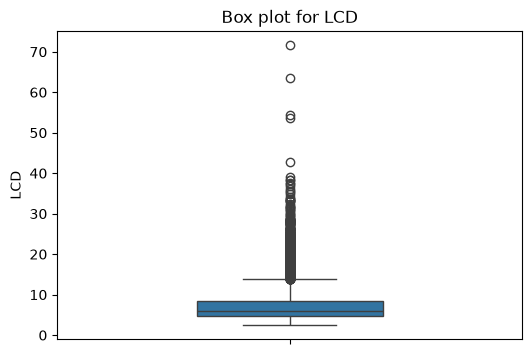

Признак: PLD
Количество выбросов по методу z-score: 213
Количество выбросов по методу IQR: 784
count    784.000000
mean      13.163225
std        5.286954
min        9.577460
25%       10.338385
50%       11.099620
75%       13.729360
max       71.501968
Name: PLD, dtype: float64


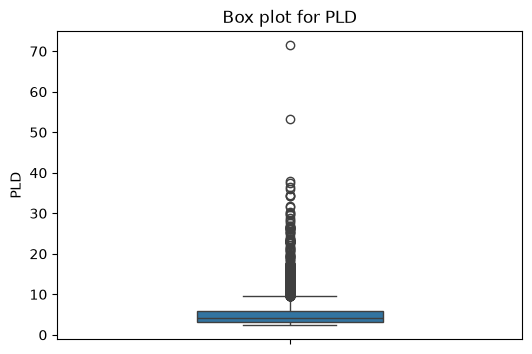

Признак: LFPD
Количество выбросов по методу z-score: 262
Количество выбросов по методу IQR: 854
count    854.000000
mean      18.532785
std        5.529502
min       13.618460
25%       15.033165
50%       16.846425
75%       20.258625
max       71.641190
Name: LFPD, dtype: float64


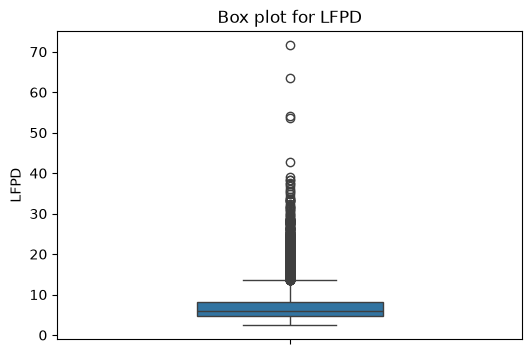

Признак: cm3_g
Количество выбросов по методу z-score: 173
Количество выбросов по методу IQR: 361
count    361.000000
mean       3.032251
std        0.599306
min        0.056920
25%        2.661030
50%        2.877280
75%        3.284030
max        7.455660
Name: cm3_g, dtype: float64


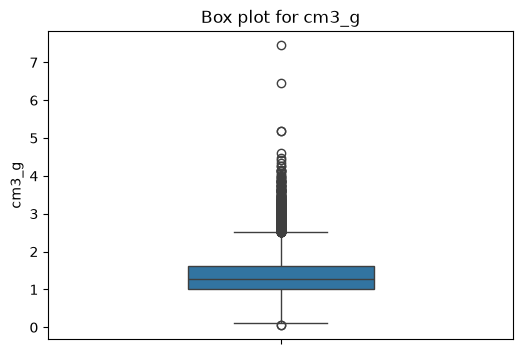

Признак: ASA_m2_g
Количество выбросов по методу z-score: 219
Количество выбросов по методу IQR: 306
count     306.000000
mean     5012.210938
std       575.671570
min      4329.620117
25%      4629.605103
50%      4891.739990
75%      5186.164795
max      8318.179688
Name: ASA_m2_g, dtype: float64


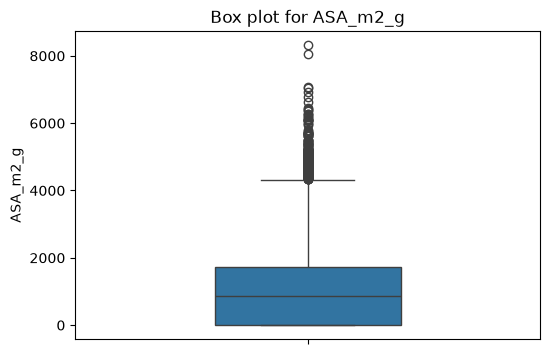

In [81]:
target_features = ['LCD','PLD','LFPD', 'cm3_g','ASA_m2_g']
for col in target_features:
    if col in df.columns:
        print(f"Признак: {col}")
        # 1. Метод z-score
        df['z_score'] = zscore(df[col])
        df_outliers_z = df[abs(df['z_score']) > 3]
        print(f"Количество выбросов по методу z-score: {len(df_outliers_z)}")

        # 2. Метод IQR
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        df['is_outlier_iqr'] = (df[col] < (Q1 - 1.5 * IQR)) | (df[col] > (Q3 + 1.5 * IQR))
        df_outliers_iqr = df[df['is_outlier_iqr']] 
        print(f"Количество выбросов по методу IQR: {len(df_outliers_iqr)}")

        print(df_outliers_iqr[col].describe())

        plt.figure(figsize=(6, 4))
        sns.boxplot(y=df[col],width=0.4)
        plt.title(f"Box plot for {col}")
        plt.ylabel(col)
        plt.show()
        
        

### Разбор аномалий на основе графиков

** Физические выбросы  (`LCD`, `PLD`, `LFPD`, `cm3_g`,`ASA_m2_g`):**
* Графики показывают длинные хвосты с точками. 
* Это не технические ошибки, а реальные физические свойства — редкие ультрапористые MOF-структуры с огромными порами.
* Удалять их нельзя, иначе потеряем ценные уникальные материалы.




### Распределение физико-химических признаков

Анализ формы распределения каждого параметра для понимания характера данных и оценки их симметричности.

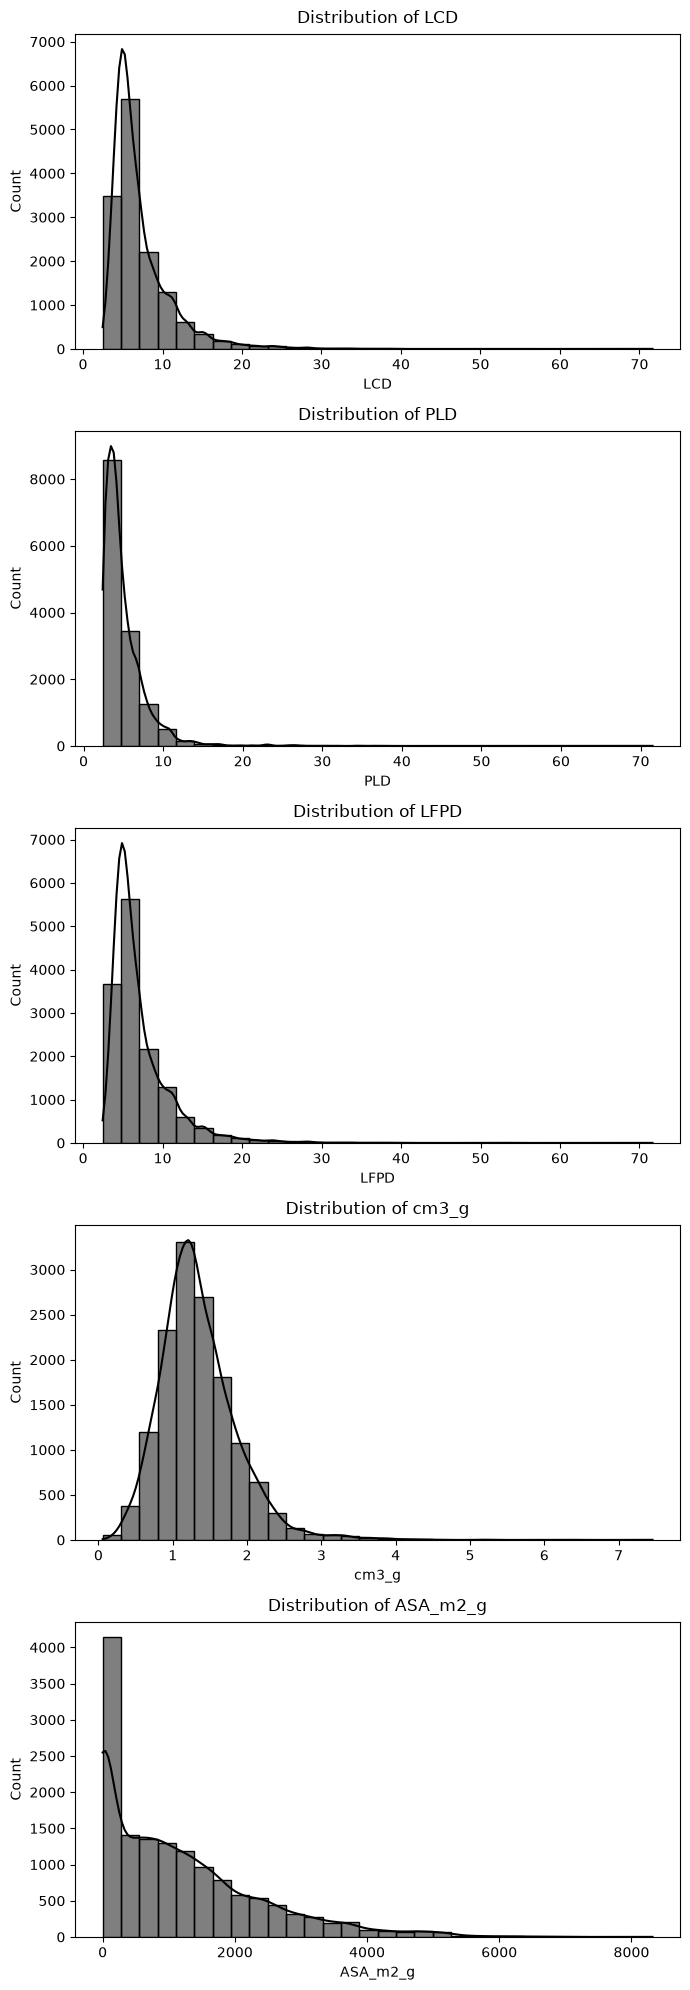

In [82]:
fig, axes = plt.subplots(nrows=5, ncols=1, figsize=(7, 20))

for idx, col in enumerate(target_features):
    if col in df.columns:
        sns.histplot(
            data=df, 
            x=col, 
            kde=True, 
            color='black', 
            bins=30, 
            ax=axes[idx]
        )
        
        axes[idx].set_title(f"Distribution of {col}", fontsize=12, pad=8)
        axes[idx].set_xlabel(col)
        axes[idx].set_ylabel("Count")

fig.tight_layout()
plt.show()

### Анализ распределения признаков

Форма гистограмм показывает реальный характер физических параметров MOF:

* **LCD, PLD, LFPD (Размеры пор):** Все три графика имеют выраженную правостороннюю асимметрию. Подавляющее большинство структур имеют мелкие поры, что особенно заметно по графику `LCD` с пиком в районе 5–6. Любые значения параметров выше 20 для этих признаков являются редкими единичными случаями, образующими длинный «хвост» распределения.
* **cm3_g (Объем пор):** Единственный параметр, который имеет нормальное распределение с пиком в районе 1.2 см³/г. В отличие от размеров пор, объём распределен равномерно, без резких перекосов в минимальные значения.
* **ASA_m2_g (Площадь поверхности):** Вместо нормального распределения виден огромный изолированный пик около нуля. Это означает, что в датасете есть огромный пласт структур, которые практически не имеют доступной площади поверхности (непористые или закрытые каркасы), хотя геометрические пустоты (`LCD`) у них могут быть отличны от нуля. Остальная часть распределения спадает плавно.

## 4. Анализ взаимосвязей признаков (матрица корреляции)

Оценка взаимосвязей между числовыми физико-химическими свойствами MOF с помощью корреляции Спирмена.


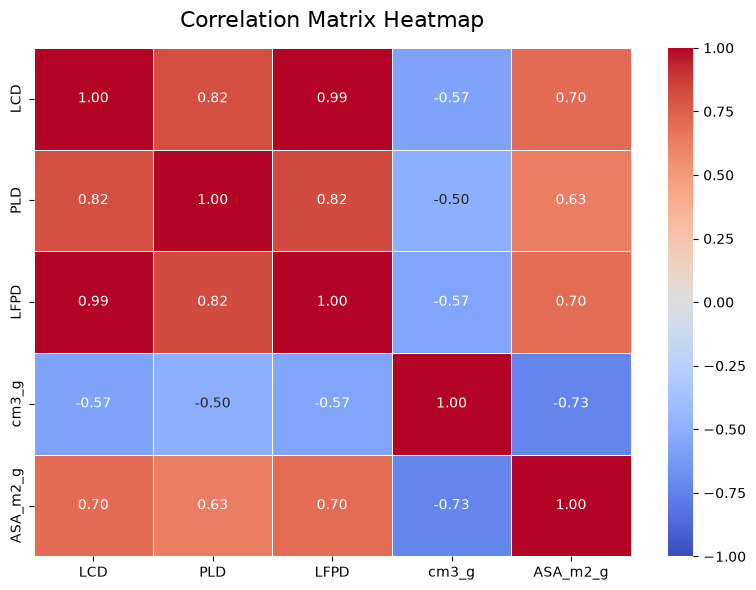

In [83]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.set_title('Correlation Matrix Heatmap', fontsize=16, pad=15)
sns.heatmap(df[target_features].corr(), annot=True, cmap='coolwarm',fmt=".2f",linewidths=0.5, vmin=-1, vmax=1, ax=ax)
fig.tight_layout()
plt.show() 

### Анализ матрицы корреляции

Геометрические связи между параметрами пор MOF:

* **Связь между LCD и LFPD (0.99):** Практически максимальная корреляция. При увеличении наибольшего диаметра полости (`LCD`) пропорционально увеличивается и свободный пробег внутри структуры (`LFPD`).
* **Связь с PLD (0.82):** Предельный диаметр пор (`PLD`) сильно связан с остальными размерами полостей. Коэффициент ниже, так как `PLD` определяет самое узкое место в канале, которое может меняться независимо от крупных пустот.
* **Связь с площадью поверхности ASA_m2_g (0.63 — 0.70):** Зависимость прямая. Рост размеров пор в материале приводит к увеличению доступной площади поверхности.
* **Отрицательная корреляция объема пор cm3_g (от -0.50 до -0.73):** Объем пор на грамм вещества снижается при росте геометрических размеров пор и площади поверхности. Это может быть связано с тем, что структуры с более крупными полостями состоят из более тяжелых металлов или массивных органических соединений. Масса самого каркаса растет быстрее, чем внутренний объем пустот, поэтому удельный показатель на грамм веса уменьшается.



## 5. Итоговый отчет по качеству данных 

* **Полнота признаков:** Основные структурные параметры пор заполнены на 100%.
* **Оптимизация:** Успешно удалено 25 мусорных колонок метаданных внешних каталогов. Размерность сокращена с 42 до 17 столбцов.
* **Качество данных:** Выбросы показывают не технические ошибки, а реальные физические свойства.
* **Форма распределений:** Геометрические размеры пор имеют сильную асимметрию с пиком у мелких значений, объем пор распределен нормально, а у площади поверхности обнаружен аномальный изолированный пик около нуля.
* **Взаимосвязи признаков:** Геометрические размеры пор имеют сильную прямую связь между собой и с площадью поверхности. При этом объем пор показывает обратную зависимость со всеми остальными параметрами.

